# Module 2 — Random Variables and Probability Distributions

**Probability Simulation Laboratory** · Module 2 of 8

## Learning objectives
1. define a random variable as a function $X:\Omega\to\mathbb R$ and distinguish discrete from continuous ones;
2. work with the pmf $p_X$, pdf $f_X$ and cdf $F_X$ and understand how they relate;
3. compute $\mathbb E[X]$, $\operatorname{Var}X$, skewness and kurtosis and the moment-generating function (MGF) $M_X(t)$;
4. know eleven standard distributions (Bernoulli, Binomial, Geometric, Poisson, Uniform, Exponential, Normal, Gamma, Beta, Lognormal, Student $t$) and compare theory with simulation;
5. generate random variables by *inverse transform sampling* and correlated normals by *Cholesky factorisation* (bridges to Modules 5 and 8);
6. explain why uncorrelated does **not** imply independent.

## Research objective
Investigate the properties of different probability distributions and compare their theoretical characteristics with simulated observations.

> Exercises should be attempted on paper before reading the code. Simulation provides evidence and intuition, not proof.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "02_probability_distributions" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import distributions as d     # 02_probability_distributions/src/distributions.py
dists = d.default_distributions()
print(len(dists), "distributions:", ", ".join(dists))

11 distributions: Bernoulli(0.3), Binomial(10, 0.3), Geometric(0.2), Poisson(4), Uniform(0, 1), Exponential(rate 1.5), Normal(1, 2^2), Gamma(2, scale 1.5), Beta(2, 5), Lognormal(0, 0.5^2), Student t(5)


## 1. Mathematical background

**Random variable.** A random variable is a (measurable) function $X:\Omega\to\mathbb R$. Its *distribution* is the probability measure $P_X(B)=P(X\in B)$.

**Discrete case.** $X$ takes countably many values; the *probability mass function* is $p_X(x)=P(X=x)$ with $p_X\ge0$, $\sum_x p_X(x)=1$.

**Continuous case.** There is a *probability density function* $f_X\ge0$ with $\int_{-\infty}^{\infty}f_X=1$ and $P(a<X\le b)=\int_a^b f_X(x)\,dx$.
$f_X(x)$ is **not** a probability (it can exceed 1); $P(X=x)=0$ for every single $x$.

**Cumulative distribution function.** $F_X(x)=P(X\le x)$: non-decreasing, right-continuous, limits $0$ and $1$. For continuous $X$, $f_X=F_X'$; for discrete $X$, $F_X$ is a step function and $P(a<X\le b)=F_X(b)-F_X(a)$.

**Expectation, variance, moments.**
$$\mathbb E[X]=\sum_x x\,p_X(x)\ \ \text{or}\ \ \int x f_X(x)\,dx,\qquad \operatorname{Var}X=\mathbb E[(X-\mu)^2]=\mathbb E[X^2]-\mu^2.$$
The $k$-th raw moment is $\mathbb E[X^k]$. With $\sigma=\sqrt{\operatorname{Var}X}$:
$$\text{skewness}=\mathbb E\!\left[\left(\tfrac{X-\mu}{\sigma}\right)^3\right],\qquad \text{excess kurtosis}=\mathbb E\!\left[\left(\tfrac{X-\mu}{\sigma}\right)^4\right]-3.$$
Skewness measures asymmetry; excess kurtosis measures tail heaviness relative to a normal (which has $0$). *Moments may not exist*: a Student-$t_\nu$ has a finite $k$-th moment only for $k<\nu$.

**Moment-generating function.** $M_X(t)=\mathbb E[e^{tX}]$, when finite for $t$ in an open interval around $0$. Then $M_X^{(k)}(0)=\mathbb E[X^k]$, and the MGF characterises the distribution; for independent $X,Y$, $M_{X+Y}=M_XM_Y$. (The lognormal has *no* MGF on any neighbourhood of $0$ even though all its moments exist.)

| Distribution | pmf / pdf | Mean | Variance | MGF |
|---|---|---|---|---|
| Bernoulli($p$) | $p^x(1-p)^{1-x}$ | $p$ | $p(1-p)$ | $1-p+pe^t$ |
| Binomial($n,p$) | $\binom nk p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ | $(1-p+pe^t)^n$ |
| Geometric($p$), $x\ge1$ | $(1-p)^{x-1}p$ | $1/p$ | $(1-p)/p^2$ | $\frac{pe^t}{1-(1-p)e^t}$ |
| Poisson($\lambda$) | $e^{-\lambda}\lambda^k/k!$ | $\lambda$ | $\lambda$ | $\exp(\lambda(e^t-1))$ |
| Uniform($a,b$) | $\frac1{b-a}$ | $\frac{a+b}2$ | $\frac{(b-a)^2}{12}$ | $\frac{e^{tb}-e^{ta}}{t(b-a)}$ |
| Exponential($\lambda$) | $\lambda e^{-\lambda x}$ | $1/\lambda$ | $1/\lambda^2$ | $\frac{\lambda}{\lambda-t}$, $t<\lambda$ |
| Normal($\mu,\sigma^2$) | $\frac1{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/2\sigma^2}$ | $\mu$ | $\sigma^2$ | $e^{\mu t+\sigma^2t^2/2}$ |
| Gamma($k,\theta$) | $\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k}$ | $k\theta$ | $k\theta^2$ | $(1-\theta t)^{-k}$, $t<1/\theta$ |
| Beta($a,b$) | $\frac{x^{a-1}(1-x)^{b-1}}{B(a,b)}$ | $\frac a{a+b}$ | $\frac{ab}{(a+b)^2(a+b+1)}$ | no simple form |
| Lognormal($\mu,\sigma^2$) | $\frac1{x\sigma\sqrt{2\pi}}e^{-(\ln x-\mu)^2/2\sigma^2}$ | $e^{\mu+\sigma^2/2}$ | $(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$ | does not exist |
| Student $t_\nu$ | $\propto(1+x^2/\nu)^{-(\nu+1)/2}$ | $0$ ($\nu>1$) | $\frac{\nu}{\nu-2}$ ($\nu>2$) | does not exist |

**Worked example.** $X\sim\text{Exponential}(\lambda)$. $M_X(t)=\int_0^\infty e^{tx}\lambda e^{-\lambda x}dx=\frac{\lambda}{\lambda-t}$ for $t<\lambda$.
Then $M'(t)=\frac{\lambda}{(\lambda-t)^2}$, so $\mathbb E X=M'(0)=\frac1\lambda$; $M''(t)=\frac{2\lambda}{(\lambda-t)^3}$, so $\mathbb E X^2=\frac2{\lambda^2}$ and
$\operatorname{Var}X=\frac2{\lambda^2}-\frac1{\lambda^2}=\frac1{\lambda^2}$. Experiment 2.3 reproduces this numerically.

**Parameterisation warning (code).** `scipy.stats` uses `loc`/`scale`: `expon(scale=1/rate)`, `gamma(k, scale=theta)`,
`lognorm(s=sigma, scale=exp(mu))`. Misreading a parameter is the most common bug in simulation code — always check simulated moments against theory.

## Experiment 2.1

**A. Experiment title.** Comparison of theoretical and simulated mean, variance, skewness and excess kurtosis for eleven distributions; and the instability of sample kurtosis under heavy tails.

**B. Research question.** Do sample moments reproduce theoretical moments, and do all moments converge equally well?

**C. Mathematical foundation.**

By the Law of Large Numbers (Module 3) the sample mean converges to $\mu$ with $\operatorname{SE}=\sigma/\sqrt n$. Sample variance, skewness and kurtosis are averages of
$(X-\bar X)^2$, $(X-\bar X)^3$, $(X-\bar X)^4$; the sample $k$-th moment has finite variance only if $\mathbb E X^{2k}<\infty$. For the Student $t_5$:
$\mathbb E|X|^k<\infty$ only for $k<5$, so the fourth moment exists (excess kurtosis $=6/(\nu-4)=6$) but $\mathbb E X^8=\infty$, so the *sample kurtosis has infinite variance* —
it converges, but erratically and slowly.

**D. Theoretical prediction.**

Sample means lie within $\approx3$ standard errors of $\mu$. Variance, skewness and kurtosis estimates are accurate for light-tailed laws (Normal, Uniform, Beta, Binomial)
but noisier for skewed/heavy-tailed laws (Exponential, Gamma, Lognormal, $t_5$), with the sample kurtosis of $t_5$ displaying large dispersion across replications.

**E. Experimental design.**

(i) Draw $n=300{,}000$ from each distribution and tabulate theoretical vs simulated moments, with the mean error in standard-error units.
(ii) Repeat a $50{,}000$-draw experiment $300$ times for Normal, Lognormal and $t_5$ to study the sampling distribution of the excess-kurtosis estimator.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

In [3]:
# F. Implementation ------------------------------------------------------------------
# d.theoretical_moments(dist) -> exact moments from scipy;  d.sample_moments(x) -> sample estimates
n = 300_000
table = d.moment_table(dists, n, rng)
table["z_mean"] = (table.mean_sim - table.mean_theory) / np.sqrt(table.var_theory / n)   # error in standard errors
table.to_csv(RESULTS / "exp2_1_moment_table.csv")

# G. Results ------------------------------------------------------------------------
display(table.round(4))
print("largest |z| for the mean:", round(float(table.z_mean.abs().max()), 2))

largest |z| for the mean: 2.12


,mean_theory,mean_sim,var_theory,var_sim,skew_theory,skew_sim,ex_kurt_theory,ex_kurt_sim,z_mean
distribution,,,,,,,,,
Bernoulli(0.3),0.3000,0.3018,0.2100,0.2107,0.8729,0.8637,-1.2381,-1.2541,2.1195
"Binomial(10, 0.3)",3.0000,3.0008,2.1000,2.1086,0.2760,0.2785,-0.1238,-0.1170,0.3087
Geometric(0.2),5.0000,4.9987,20.0000,20.0551,2.0125,2.0423,6.0500,6.3471,-0.1547
Poisson(4),4.0000,4.0033,4.0000,4.0075,0.5000,0.4993,0.2500,0.2456,0.9037
"Uniform(0, 1)",0.5000,0.5003,0.0833,0.0833,0.0000,-0.0026,-1.2000,-1.1994,0.6311
Exponential(rate 1.5),0.6667,0.6669,0.4444,0.4441,2.0000,1.9881,6.0000,5.8993,0.1558
"Normal(1, 2^2)",1.0000,0.9970,4.0000,3.9943,0.0000,0.0072,0.0000,0.0057,-0.8271
"Gamma(2, scale 1.5)",3.0000,3.0026,4.5000,4.4901,1.4142,1.3990,3.0000,2.8882,0.6609
"Beta(2, 5)",0.2857,0.2853,0.0255,0.0254,0.5963,0.5936,-0.1200,-0.1135,-1.5541


,theory,mean_of_estimates,sd_of_estimates,minimum,maximum
distribution,,,,,
"Normal(1, 2^2)",0.000,-0.000,0.022,-0.067,0.064
"Lognormal(0, 0.5^2)",5.898,5.948,0.893,4.525,13.026
Student t(5),6.000,5.308,2.462,2.816,20.801


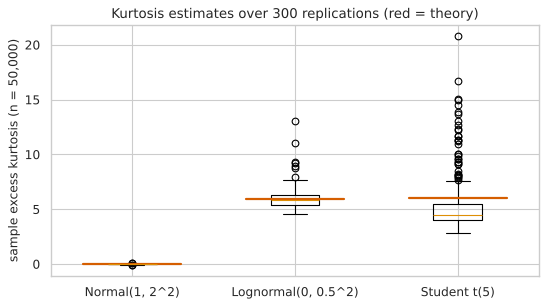

PosixPath('/home/claude/probability-simulation-laboratory/02_probability_distributions/results/exp2_1_kurtosis_stability.png')

In [4]:
# Sampling distribution of the excess-kurtosis estimator
reps, m = 300, 50_000
rows, store = [], {}
for name in ["Normal(1, 2^2)", "Lognormal(0, 0.5^2)", "Student t(5)"]:
    ks = np.array([stats.kurtosis(d.draw_samples(dists[name], m, rng)) for _ in range(reps)])
    store[name] = ks
    rows.append(dict(distribution=name, theory=d.theoretical_moments(dists[name])["ex_kurt"], mean_of_estimates=ks.mean(),
                     sd_of_estimates=ks.std(ddof=1), minimum=ks.min(), maximum=ks.max()))
kurt_table = pd.DataFrame(rows).set_index("distribution")
kurt_table.to_csv(RESULTS / "exp2_1_kurtosis_stability.csv")
display(kurt_table.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(list(store.values()), tick_labels=list(store.keys()))
for i, name in enumerate(store, start=1):
    ax.plot([i - 0.3, i + 0.3], [kurt_table.loc[name, "theory"]] * 2, "r-", lw=2)
ax.set(ylabel="sample excess kurtosis (n = 50,000)", title="Kurtosis estimates over 300 replications (red = theory)")
fig.tight_layout(); save_fig(fig, RESULTS, "exp2_1_kurtosis_stability.png")

**H. Theoretical versus empirical comparison.**

The mean column agrees with theory within a few standard errors in every row (see `z_mean`), variances and skewness agree to roughly two to three significant digits for the light-tailed laws,
and larger relative discrepancies appear for skewness/kurtosis of the lognormal and $t_5$ (the quantities with the heaviest tails). The replication study shows the spread of kurtosis estimates is small for the Normal,
larger for the Lognormal, and largest and most irregular for $t_5$, where occasional extreme draws make individual estimates far from the theoretical value $6$.

**I. Interpretation.**

"The sample moment converges to the population moment" is true whenever the population moment exists — but the *speed and reliability* depend on how many higher moments exist.
In finance, return distributions have fat tails (Module 8): sample kurtosis from a few years of data is a notoriously unreliable statistic, and
inference based on it should be treated cautiously.

**J. Limitations.**

Pseudo-random draws; one fixed seed; sample moments for finite $n$ are biased (e.g. sample skewness and kurtosis have small-sample bias, ignored here because $n$ is large).
The theoretical moments rely on `scipy` formulas — a bug there would be shared by "theory" and could only be caught by deriving them independently (Exercise 2).

**K. Research conclusion.**

The first four sample moments of all eleven distributions agree with theory; the reliability of higher sample moments degrades as tails get heavier.

**L. Further investigation.**

Estimate how large $n$ must be for the relative error of the sample kurtosis of $t_5$ to be below $10\%$ with probability $0.9$. Repeat for $t_{4.2}$ and $t_{3}$ (where the fourth moment is infinite).

## Experiment 2.2

**A. Experiment title.** Empirical versus theoretical pmf/pdf and cdf: the Kolmogorov distance $\sup_t|F_n(t)-F(t)|$ and the total-variation distance.

**B. Research question.** Does a histogram of simulated data reproduce the pmf/pdf, and how can the discrepancy be measured?

**C. Mathematical foundation.**

The *empirical cdf* is $F_n(t)=\frac1n\#\{i:X_i\le t\}$. By the Glivenko–Cantelli theorem $\sup_t|F_n(t)-F(t)|\to0$ almost surely; the Dvoretzky–Kiefer–Wolfowitz inequality gives
$P\big(\sup_t|F_n(t)-F(t)|>\varepsilon\big)\le2e^{-2n\varepsilon^2}$, so with $95\%$ confidence the Kolmogorov distance is below $\varepsilon_n=\sqrt{\ln(40)/(2n)}$ — about $0.0043$ for $n=100{,}000$.
For discrete laws we use the total-variation distance $\frac12\sum_k|\hat p(k)-p(k)|$. Also: a pdf is a *density*: for Beta$(2,5)$ the maximum is $30\cdot0.2\cdot0.8^4\approx2.46>1$.

**D. Theoretical prediction.**

For $n=100{,}000$ and a correct model, each continuous distribution should have Kolmogorov distance below about $0.0043$ (with probability 95% each) and p-values spread over $(0,1)$;
discrete laws should have small total-variation distance (of order $\sqrt{K/n}$ with $K$ support points).

**E. Experimental design.**

Draw $100{,}000$ samples from each distribution, overlay histogram on theoretical pmf/pdf in a $3\times4$ panel figure, and tabulate KS statistics (continuous) and TV distances (discrete).

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

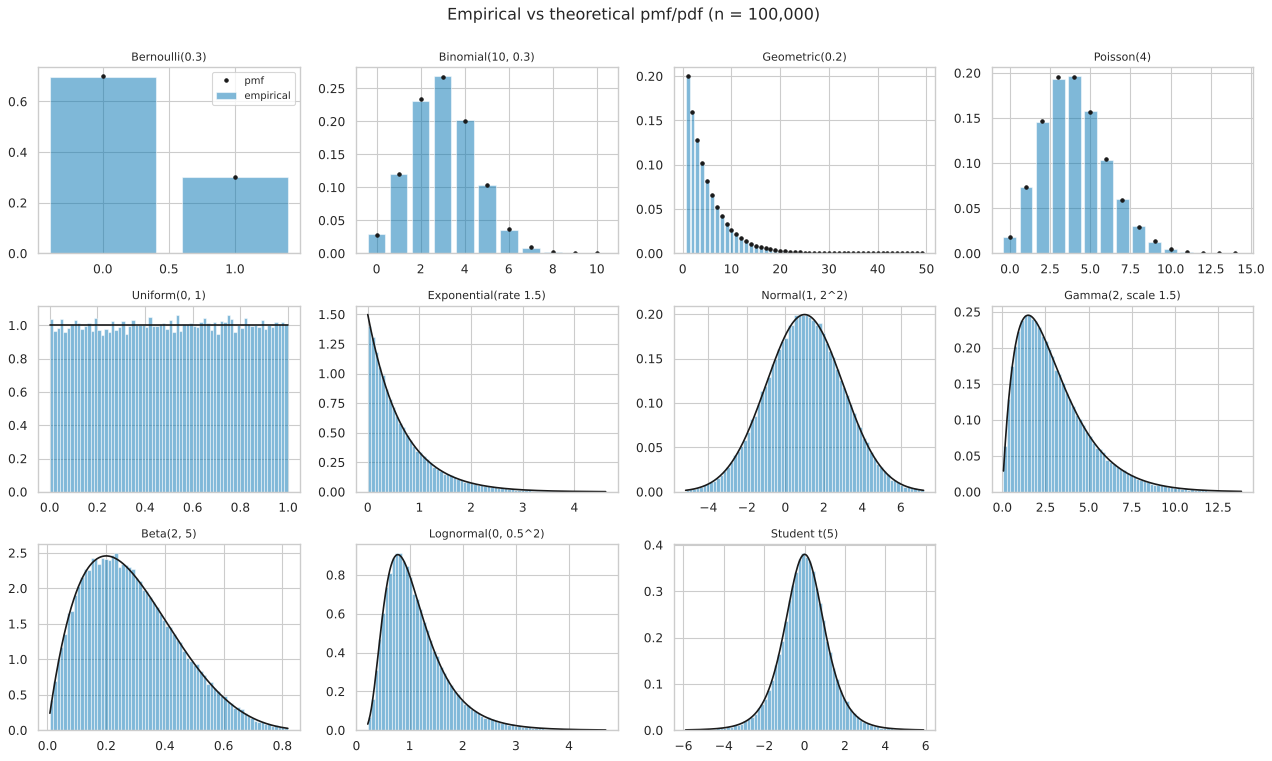

PosixPath('/home/claude/probability-simulation-laboratory/02_probability_distributions/results/exp2_2_pmf_pdf_panels.png')

In [5]:
# F/G. Implementation and results -----------------------------------------------------
n = 100_000
samples = {name: d.draw_samples(dist, n, rng) for name, dist in dists.items()}

fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
axes = axes.ravel()
for ax, (name, dist) in zip(axes, dists.items()):
    x = samples[name]
    if d.is_discrete(dist):
        ks_ = np.arange(x.min(), x.max() + 1)
        emp = np.bincount((x - x.min()).astype(int), minlength=ks_.size) / n
        ax.bar(ks_, emp, alpha=0.5, label="empirical")
        ax.plot(ks_, dist.pmf(ks_), "ko", ms=3, label="pmf")
    else:
        lo, hi = dist.ppf([0.001, 0.999])
        ax.hist(x, bins=70, range=(lo, hi), density=True, alpha=0.5, label="empirical")
        grid = np.linspace(lo, hi, 400)
        ax.plot(grid, dist.pdf(grid), "k", lw=1.5, label="pdf")
    ax.set_title(name, fontsize=10)
axes[0].legend()
axes[-1].axis("off")
fig.suptitle("Empirical vs theoretical pmf/pdf (n = 100,000)", y=1.0)
fig.tight_layout(); save_fig(fig, RESULTS, "exp2_2_pmf_pdf_panels.png")

In [6]:
# H. Theoretical vs empirical: KS (continuous) and TV (discrete)
eps95 = np.sqrt(np.log(40) / (2 * n))      # DKW 95% bound
rows = []
for name, dist in dists.items():
    x = samples[name]
    if d.is_discrete(dist):
        rows.append(dict(distribution=name, kind="discrete", statistic="TV distance", value=d.tv_distance_discrete(x, dist), p_value=np.nan))
    else:
        ksv, pv = d.ks_test(x, dist)
        rows.append(dict(distribution=name, kind="continuous", statistic="KS distance", value=ksv, p_value=pv))
fit = pd.DataFrame(rows).set_index("distribution")
fit.to_csv(RESULTS / "exp2_2_goodness_of_fit.csv")
display(fit)
print(f"DKW 95% bound for n = {n:,}: {eps95:.5f}")
print("continuous distributions with KS above the DKW bound:", int((fit.query("kind == 'continuous'").value > eps95).sum()), "of 7")
print("max pdf of Beta(2,5):", round(float(dists['Beta(2, 5)'].pdf(0.2)), 4), "(a density can exceed 1)")
a, b = 1.0, 3.0
from scipy import integrate
g = dists["Gamma(2, scale 1.5)"]
print("Gamma: P(1 < X <= 3) via cdf:", round(float(g.cdf(b) - g.cdf(a)), 5), "| via integrating the pdf:", round(integrate.quad(g.pdf, a, b)[0], 5),
      "| simulated:", round(float(np.mean((samples['Gamma(2, scale 1.5)'] > a) & (samples['Gamma(2, scale 1.5)'] <= b))), 5))

DKW 95% bound for n = 100,000: 0.00429
continuous distributions with KS above the DKW bound: 0 of 7
max pdf of Beta(2,5): 2.4576 (a density can exceed 1)
Gamma: P(1 < X <= 3) via cdf: 0.44969 | via integrating the pdf: 0.44969 | simulated: 0.4495


,kind,statistic,value,p_value
distribution,,,,
Bernoulli(0.3),discrete,TV distance,0.00302,NaN
"Binomial(10, 0.3)",discrete,TV distance,0.00515,NaN
Geometric(0.2),discrete,TV distance,0.00468,NaN
Poisson(4),discrete,TV distance,0.00476,NaN
"Uniform(0, 1)",continuous,KS distance,0.00343,0.18879
Exponential(rate 1.5),continuous,KS distance,0.00241,0.60343
"Normal(1, 2^2)",continuous,KS distance,0.00160,0.95949
"Gamma(2, scale 1.5)",continuous,KS distance,0.00188,0.87191
"Beta(2, 5)",continuous,KS distance,0.00268,0.46641


**H. Theoretical versus empirical comparison.**

Panels overlay closely. The continuous Kolmogorov distances are of the order $10^{-3}$ — compare with the DKW bound printed above; a correct model will occasionally
exceed a 95% bound (about one distribution in twenty) purely by chance. The p-values are not expected to be large: they should look like draws from Uniform$(0,1)$.
The Gamma probability computed from the cdf, by integrating the pdf, and by simulation agree, confirming $P(a<X\le b)=F(b)-F(a)=\int_a^bf$.

**I. Interpretation.**

Goodness of fit is about *distance*: with a large sample even tiny model errors become statistically detectable, and with a small sample large ones can be missed. The DKW bound
quantifies how far an empirical cdf can wander from the truth: it shrinks like $n^{-1/2}$, the same rate we met in Module 1.

**J. Limitations.**

KS p-values are only valid when the distribution is fully specified in advance (not fitted to the same data — then the Lilliefors correction is required). TV distance for
discrete laws has a positive bias of order $\sqrt{K/n}$ even when the model is correct.

**K. Research conclusion.**

Simulated data from all eleven generators agree with their theoretical pmf/pdf/cdf up to the sampling error predicted by the DKW inequality (continuous) or $\approx\sqrt{K/n}$ (discrete).

**L. Further investigation.**

Fit the same distributions to *simulated* data from a different family (e.g. Gamma data, Lognormal model) and see how large $n$ is needed for KS to reject.

## Experiment 2.3

**A. Experiment title.** Empirical versus closed-form moment-generating function $M_X(t)=\mathbb E[e^{tX}]$, and recovery of moments from derivatives at $0$.

**B. Research question.** Can $M_X(t)$ be estimated by Monte Carlo, and do its derivatives at $0$ return the mean and variance?

**C. Mathematical foundation.**

$M_X(t)=\mathbb E[e^{tX}]$ is an expectation, so it is estimated by $\hat M(t)=\frac1n\sum_i e^{tX_i}$ with
$\operatorname{SE}=\operatorname{sd}(e^{tX})/\sqrt n$. The variance of $e^{tX}$ is $M_X(2t)-M_X(t)^2$, which is finite only if $2t$ lies inside the MGF's domain;
it grows rapidly near the boundary. Moments: $M'(0)=\mathbb E X$, $M''(0)=\mathbb E X^2$; central differences give $\frac{M(h)-M(-h)}{2h}$ and $\frac{M(h)-2M(0)+M(-h)}{h^2}$ with error $O(h^2)$.

**D. Theoretical prediction.**

$\hat M(t)$ matches the closed form within a small relative error on $t\in[-1,0.3]$; the discrepancy is larger for larger $t$ and for heavier-tailed variables
(Exponential and Gamma near their MGF boundaries). Finite-difference moments from the closed-form MGFs reproduce the mean and variance to $\approx10^{-6}$ relative accuracy.

**E. Experimental design.**

For the seven distributions with a closed-form MGF, estimate $\hat M(t)$ on $27$ values of $t\in[-1,0.3]$ from $400{,}000$ draws and compare. Then differentiate each closed-form MGF numerically at $0$.
(A symbolic derivation with SymPy is included as an extra cell.)

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,max_relative_error,relative_error_at_t_max
distribution,,
Bernoulli(0.3),0.00027,0.00011
"Binomial(10, 0.3)",0.00129,0.00036
Poisson(4),0.00235,0.00004
Exponential(rate 1.5),0.00038,0.00006
"Normal(1, 2^2)",0.00500,0.00055
"Gamma(2, scale 1.5)",0.00644,0.00644
"Uniform(0, 1)",0.00034,0.00014


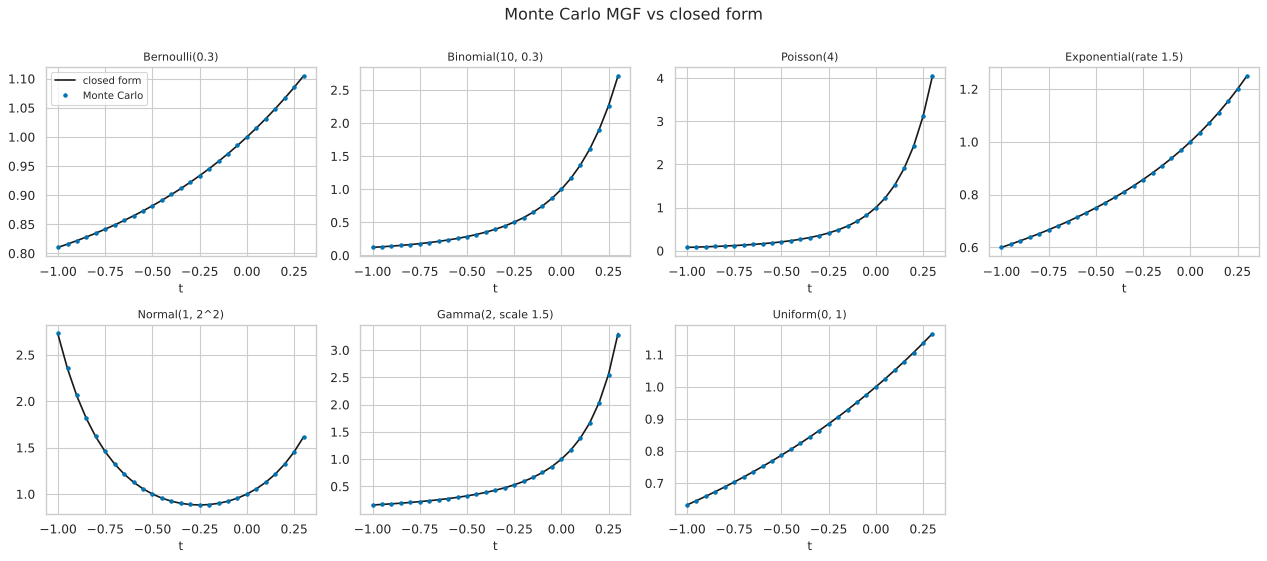

In [7]:
# F/G. Implementation and results ---------------------------------------------------------
cat = d.mgf_catalogue()
t_grid = np.linspace(-1.0, 0.3, 27)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
rows = []
for ax, (name, (dist, mgf)) in zip(axes, cat.items()):
    x = d.draw_samples(dist, 400_000, rng)
    emp = d.empirical_mgf(x, t_grid)
    th = mgf(t_grid)
    ax.plot(t_grid, th, "k", label="closed form")
    ax.plot(t_grid, emp, "o", ms=3, label="Monte Carlo")
    ax.set_title(name, fontsize=10); ax.set_xlabel("t")
    rows.append(dict(distribution=name, max_relative_error=float(np.max(np.abs(emp / th - 1))),
                     relative_error_at_t_max=float(abs(emp[-1] / th[-1] - 1))))
axes[0].legend(); axes[-1].axis("off")
fig.suptitle("Monte Carlo MGF vs closed form", y=1.0)
fig.tight_layout(); save_fig(fig, RESULTS, "exp2_3_mgf.png")
mgf_table = pd.DataFrame(rows).set_index("distribution")
display(mgf_table)

In [8]:
# H. Theoretical vs empirical: moments from derivatives of the closed-form MGF at t = 0
rows = []
for name, (dist, mgf) in cat.items():
    mean_fd, var_fd = d.mgf_moments_finite_difference(mgf)
    rows.append(dict(distribution=name, mean_from_MGF=mean_fd, mean_exact=float(dist.mean()),
                     var_from_MGF=var_fd, var_exact=float(dist.var())))
mgf_moments = pd.DataFrame(rows).set_index("distribution")
mgf_moments.to_csv(RESULTS / "exp2_3_mgf_moments.csv")
display(mgf_moments)

,mean_from_MGF,mean_exact,var_from_MGF,var_exact
distribution,,,,
Bernoulli(0.3),0.30000,0.30000,0.21000,0.21000
"Binomial(10, 0.3)",3.00001,3.00000,2.09997,2.10000
Poisson(4),4.00002,4.00000,3.99991,4.00000
Exponential(rate 1.5),0.66667,0.66667,0.44444,0.44444
"Normal(1, 2^2)",1.00000,1.00000,4.00000,4.00000
"Gamma(2, scale 1.5)",3.00001,3.00000,4.49997,4.50000
"Uniform(0, 1)",0.50000,0.50000,0.08333,0.08333


In [ ]:
# Extra: symbolic derivation with SymPy (requires `pip install sympy`; NOT executed when this notebook was built)
import sympy as sp

t, lam = sp.symbols("t lambda", positive=True)
M = lam / (lam - t)                                   # MGF of Exponential(lambda), valid for t < lambda
mean = sp.diff(M, t).subs(t, 0)                       # M'(0)
second = sp.diff(M, t, 2).subs(t, 0)                  # M''(0) = E[X^2]
print("E[X]   =", sp.simplify(mean))                  # expected: 1/lambda
print("E[X^2] =", sp.simplify(second))                # expected: 2/lambda**2
print("Var[X] =", sp.simplify(second - mean**2))      # expected: lambda**(-2)

mu, sigma = sp.symbols("mu sigma", real=True)
Mn = sp.exp(mu * t + sigma**2 * t**2 / 2)             # Normal MGF
print("Normal mean:", sp.simplify(sp.diff(Mn, t).subs(t, 0)))                                           # mu
print("Normal variance:", sp.simplify(sp.diff(Mn, t, 2).subs(t, 0) - sp.diff(Mn, t).subs(t, 0)**2))    # sigma**2

**H. Theoretical versus empirical comparison.**

The Monte Carlo curves overlay the closed forms, with relative errors below $1\%$ everywhere. The largest errors are for the Normal (at $t=-1$, where $e^{tX}$ is itself heavy-tailed: its variance
$M(2t)-M(t)^2\approx396$ dwarfs $M(t)^2\approx7.4$) and for the Gamma at $t=0.3$, close to the boundary $t<1/(2\theta)\approx0.33$ beyond which $e^{tX}$ has infinite variance. Finite-difference moments of the closed-form MGFs match
the exact mean and variance to within the $O(h^2)$ discretisation error.

**I. Interpretation.**

The MGF encodes *all* moments in one function, and turns convolution (sums of independent variables) into multiplication — the main reason it is used to prove the Central Limit Theorem (Module 4).
Monte Carlo estimation of $M(t)$ also illustrates that expectations of *unbounded* functions ($e^{tX}$) can be hard to estimate when tails are heavy.

**J. Limitations.**

We deliberately avoided $t$ near the MGF boundary and the lognormal/Student-$t$ laws, for which no MGF exists. Finite differences use step $h=10^{-3}$: smaller $h$ amplifies floating-point
cancellation in $M''$, larger $h$ increases truncation error.

**K. Research conclusion.**

$M_X(t)=\mathbb E e^{tX}$ is simple to estimate by simulation where it exists, and its derivatives at $0$ recover the moments.

**L. Further investigation.**

Use the MGF to prove that the sum of independent Poisson($\lambda_1$) and Poisson($\lambda_2$) is Poisson($\lambda_1+\lambda_2$), then verify by simulation with a goodness-of-fit test.

## Experiment 2.4

**A. Experiment title.** Inverse transform sampling: $X=F^{-1}(U)\sim F$ and the probability integral transform $F(X)\sim\text{Uniform}(0,1)$.

**B. Research question.** How are non-uniform random variables generated from uniform random numbers, and can we verify the construction?

**C. Mathematical foundation.**

**Claim.** If $U\sim\text{Uniform}(0,1)$ and $F$ is a continuous strictly increasing cdf, then $X=F^{-1}(U)$ has cdf $F$.
*Proof.* $P(X\le x)=P(F^{-1}(U)\le x)=P(U\le F(x))=F(x)$. $\square$
Conversely, if $X$ has continuous cdf $F$, then $F(X)\sim\text{Uniform}(0,1)$ (probability integral transform).
**Exponential:** $F(x)=1-e^{-\lambda x}\Rightarrow F^{-1}(u)=-\ln(1-u)/\lambda$.
**Geometric** ($P(X>k)=(1-p)^k$): $X=\lceil\ln(1-U)/\ln(1-p)\rceil$, since $X\le k\iff U\le1-(1-p)^k$.

**D. Theoretical prediction.**

Exponential samples built from $U$ pass a KS test against Exponential($\lambda$) (p-value not small), have mean $1/\lambda$ and variance $1/\lambda^2$; geometric samples match the geometric pmf (small TV distance);
applying the true cdf to samples from any continuous law yields data indistinguishable from Uniform$(0,1)$.

**E. Experimental design.**

Draw $100{,}000$ uniforms; transform; compare with `scipy`'s exponential generator and with the exact pdf/pmf. Then apply the probability integral transform to samples from five continuous distributions and run KS tests against Uniform$(0,1)$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

theory: mean = 0.6667, variance = 0.4444
geometric via inverse transform: mean = 5.0157 (theory 5.0); TV distance to pmf = 0.00423


,mean,variance,KS,p_value
generator,,,,
inverse transform (closed form),0.66645,0.43946,0.00320,0.25625
inverse transform (scipy ppf),0.66701,0.44478,0.00382,0.10714
scipy expon.rvs,0.66933,0.44479,0.00330,0.22470


,KS_vs_Uniform,p_value
distribution,,
Exponential(rate 1.5),0.00302,0.32093
"Normal(1, 2^2)",0.00156,0.96731
"Gamma(2, scale 1.5)",0.00222,0.70772
"Beta(2, 5)",0.00335,0.21030
"Lognormal(0, 0.5^2)",0.00492,0.01561


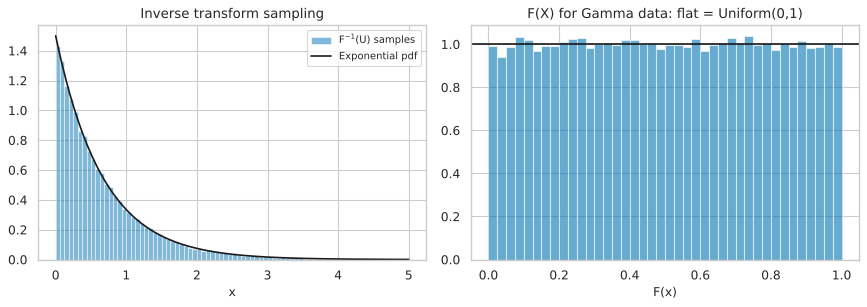

In [9]:
# F. Implementation ------------------------------------------------------------------
# F^{-1}(u) = -ln(1-u)/rate  ->  d.inverse_transform_exponential ;  generic version: d.inverse_transform_sample(ppf, n, rng)
n, rate, p_geo = 100_000, 1.5, 0.2
x_inv = d.inverse_transform_exponential(n, rate, rng)
x_ref = stats.expon(scale=1 / rate).rvs(size=n, random_state=rng)         # library generator for comparison
x_generic = d.inverse_transform_sample(stats.expon(scale=1 / rate).ppf, n, rng)
g_inv = d.inverse_transform_geometric(n, p_geo, rng)

# G. Results ------------------------------------------------------------------------
rows = []
for label, x in [("inverse transform (closed form)", x_inv), ("inverse transform (scipy ppf)", x_generic), ("scipy expon.rvs", x_ref)]:
    ksv, pv = d.ks_test(x, stats.expon(scale=1 / rate))
    rows.append(dict(generator=label, mean=x.mean(), variance=x.var(ddof=1), KS=ksv, p_value=pv))
inv_table = pd.DataFrame(rows).set_index("generator")
display(inv_table)
print(f"theory: mean = {1/rate:.4f}, variance = {1/rate**2:.4f}")
print(f"geometric via inverse transform: mean = {g_inv.mean():.4f} (theory {1/p_geo:.1f}); TV distance to pmf = {d.tv_distance_discrete(g_inv, stats.geom(p_geo)):.5f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
grid = np.linspace(0, 5, 300)
ax[0].hist(x_inv, bins=80, range=(0, 5), density=True, alpha=0.5, label="F$^{-1}$(U) samples")
ax[0].plot(grid, stats.expon(scale=1 / rate).pdf(grid), "k", label="Exponential pdf")
ax[0].set(title="Inverse transform sampling", xlabel="x"); ax[0].legend()

pit_rows = []
for name in ["Exponential(rate 1.5)", "Normal(1, 2^2)", "Gamma(2, scale 1.5)", "Beta(2, 5)", "Lognormal(0, 0.5^2)"]:
    dist = dists[name]
    u = dist.cdf(d.draw_samples(dist, n, rng))
    pit_rows.append(dict(distribution=name, KS_vs_Uniform=stats.kstest(u, "uniform").statistic, p_value=stats.kstest(u, "uniform").pvalue))
    if name == "Gamma(2, scale 1.5)":
        ax[1].hist(u, bins=40, density=True, alpha=0.6)
        ax[1].axhline(1, color="k"); ax[1].set(title="F(X) for Gamma data: flat = Uniform(0,1)", xlabel="F(x)")
fig.tight_layout(); save_fig(fig, RESULTS, "exp2_4_inverse_transform.png")
pit_table = pd.DataFrame(pit_rows).set_index("distribution")
pit_table.to_csv(RESULTS / "exp2_4_probability_integral_transform.csv")
display(pit_table)

**H. Theoretical versus empirical comparison.**

All three exponential generators have mean and variance near $0.667$ and $0.444$, with KS p-values that do not indicate a problem (they are *not* guaranteed to be large — under a correct model they are uniform).
The geometric sampler has small TV distance. The probability integral transform produces essentially flat histograms; four of the five KS tests do not reject, and the Lognormal gives a p-value of about $0.016$.
That is not a bug: with five tests, at least one p-value below $0.05$ happens about $23\%$ of the time ($1-0.95^5$), and repeating the Lognormal test over 200 different seeds gave p-values that look uniform on $(0,1)$ (about $3.5\%$ below $0.05$, as expected).
A single small p-value is a prompt to *repeat with other seeds*, not a verdict.

**I. Interpretation.**

Every continuous distribution is a *deterministic transformation* of a uniform random variable, which is why a single good uniform generator suffices. Understanding this also explains
*quantile functions* and *copulas* (used in multi-asset risk models): the probability integral transform strips away the marginal distribution and leaves only dependence.

**J. Limitations.**

The method requires a tractable $F^{-1}$ (not available in closed form for Normal or Gamma — libraries use other algorithms). $\ln(1-U)$ is computed with `log1p` to avoid cancellation. Floating-point uniforms are discrete: $2^{53}$ values.

**K. Research conclusion.**

$F^{-1}(U)$ reproduces the target distribution; $F(X)$ is uniform. Both were confirmed numerically.

**L. Further investigation.**

Implement the Box–Muller transform for standard normals, compare with `scipy`'s `ppf`-based inverse transform, and compare speed and accuracy in the tails.

## Experiment 2.5

**A. Experiment title.** Joint distributions: correlated normals via the Cholesky factor, portfolio variance, and uncorrelated-but-dependent variables.

**B. Research question.** How do we simulate dependent random variables, and does zero correlation imply independence?

**C. Mathematical foundation.**

**Covariance and correlation.** $\operatorname{Cov}(X,Y)=\mathbb E[XY]-\mathbb E X\,\mathbb E Y$, $\rho=\operatorname{Cov}(X,Y)/(\sigma_X\sigma_Y)\in[-1,1]$ ($\rho$ measures *linear* dependence only).
**Variance of a combination:** $\operatorname{Var}(aX+bY)=a^2\sigma_X^2+b^2\sigma_Y^2+2ab\rho\sigma_X\sigma_Y$.
**Cholesky simulation.** If $Z\sim\mathcal N(0,I)$ and $\Sigma=LL^\top$ with $L$ lower-triangular, then $Y=LZ$ has covariance $\mathbb E[YY^\top]=L\,\mathbb E[ZZ^\top]L^\top=LL^\top=\Sigma$.
**Independence $\Rightarrow$ zero covariance, but not conversely.** Let $X\sim\mathcal N(0,1)$ and $Y=X^2$. Then $\operatorname{Cov}(X,Y)=\mathbb E[X^3]-\mathbb E[X]\mathbb E[X^2]=0$, yet $Y$ is determined by $X$.
For *jointly normal* variables zero correlation does imply independence — normality is the special case.
**Finance link.** Two assets with weights $(0.6,0.4)$, volatilities $(0.2,0.3)$ and correlation $\rho=0.5$ have portfolio variance
$0.36(0.04)+0.16(0.09)+2(0.24)(0.2)(0.3)(0.5)=0.0432$, i.e. volatility $\approx0.2078$.

**D. Theoretical prediction.**

Sample correlation of the Cholesky pairs $\approx\rho=0.8$; sample covariance matrix $\approx\Sigma$; simulated portfolio standard deviation $\approx0.2078$ (and lower than the weighted average
volatility $0.24$ — diversification). For $(X,X^2)$: sample correlation $\approx0$ but $P(Y>1\mid|X|>1)=1\ne P(Y>1)=2(1-\Phi(1))\approx0.3173$.

**E. Experimental design.**

Draw $200{,}000$ pairs with covariance $\Sigma=\begin{pmatrix}1&0.8\\0.8&1\end{pmatrix}$; separately the two-asset portfolio; and $500{,}000$ draws of $(X,X^2)$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

target covariance:
 [[1.  0.8]
 [0.8 1. ]]
sample covariance:
 [[0.9972 0.7979]
 [0.7979 0.9984]]
sample correlation: 0.7996
portfolio variance: theory 0.04320, simulated 0.04329
portfolio volatility 0.2078 vs weighted-average volatility 0.2400 (diversification benefit)
corr(X, X^2) = 0.0039
corr(|X|, X^2) = 0.9356
P(Y > 1) = 0.3169 (theory 0.3173);  P(Y > 1 | |X| > 1) = 1.0000


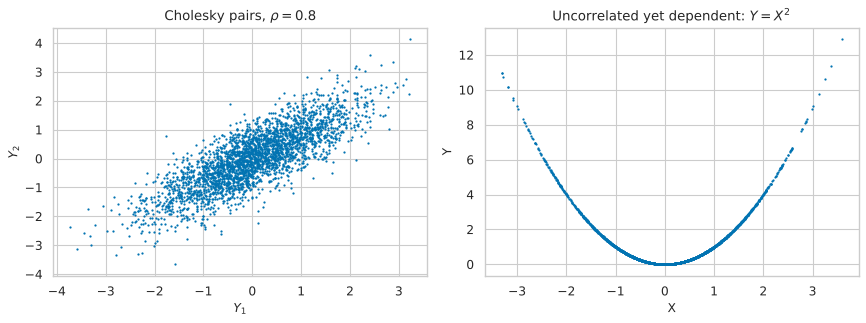

PosixPath('/home/claude/probability-simulation-laboratory/02_probability_distributions/results/exp2_5_joint.png')

In [10]:
# F. Implementation ------------------------------------------------------------------
# Sigma = L L^T  (np.linalg.cholesky);  Y = Z L^T gives rows with covariance Sigma   -> d.correlated_normals
n = 200_000
cov = np.array([[1.0, 0.8], [0.8, 1.0]])
y = d.correlated_normals(n, cov, rng)
print("target covariance:\n", cov)
print("sample covariance:\n", np.cov(y.T).round(4))
print("sample correlation:", round(float(np.corrcoef(y.T)[0, 1]), 4))

# Two-asset portfolio ------------------------------------------------------------------
w = np.array([0.6, 0.4]); vol = np.array([0.2, 0.3]); rho = 0.5
Sigma = np.array([[vol[0] ** 2, rho * vol[0] * vol[1]], [rho * vol[0] * vol[1], vol[1] ** 2]])
r = d.correlated_normals(n, Sigma, rng)
port = r @ w
print(f"portfolio variance: theory {w @ Sigma @ w:.5f}, simulated {port.var(ddof=1):.5f}")
print(f"portfolio volatility {np.sqrt(w @ Sigma @ w):.4f} vs weighted-average volatility {w @ vol:.4f} (diversification benefit)")

# Uncorrelated but dependent -----------------------------------------------------------
x, yy = d.uncorrelated_but_dependent(500_000, rng)
print(f"corr(X, X^2) = {np.corrcoef(x, yy)[0, 1]:.4f}")
print(f"corr(|X|, X^2) = {np.corrcoef(np.abs(x), yy)[0, 1]:.4f}")
big = np.abs(x) > 1
print(f"P(Y > 1) = {np.mean(yy > 1):.4f} (theory {2 * stats.norm.sf(1):.4f});  P(Y > 1 | |X| > 1) = {np.mean(yy[big] > 1):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(y[:3000, 0], y[:3000, 1], ".", ms=2); ax[0].set(title=r"Cholesky pairs, $\rho = 0.8$", xlabel="$Y_1$", ylabel="$Y_2$")
ax[1].plot(x[:3000], yy[:3000], ".", ms=2); ax[1].set(title="Uncorrelated yet dependent: $Y = X^2$", xlabel="X", ylabel="Y")
fig.tight_layout(); save_fig(fig, RESULTS, "exp2_5_joint.png")

**H. Theoretical versus empirical comparison.**

The sample covariance matrix reproduces $\Sigma$, the portfolio variance matches $0.0432$ closely, and portfolio volatility is lower than the weighted average of the two volatilities.
The $(X,X^2)$ pair has sample correlation indistinguishable from $0$, yet knowing $|X|>1$ forces $Y>1$ with probability exactly $1$.

**I. Interpretation.**

Correlation is a summary of *linear* association only. Risk models that rely solely on correlation can badly mischaracterise dependence — notably in the tails, where assets
that look uncorrelated in calm periods can crash together. This is one motivation for copulas and tail-dependence measures.

**J. Limitations.**

Cholesky requires $\Sigma$ to be positive definite; estimated covariance matrices from short samples may not be. We assumed multivariate normality, which does not hold for real returns.

**K. Research conclusion.**

Cholesky factorisation turns independent normals into correlated normals; correlation $0$ does not imply independence outside the jointly normal case.

**L. Further investigation.**

Construct two non-normal dependent variables with a prescribed correlation using a Gaussian copula and compare their joint tail behaviour with that of a bivariate normal.

## Exercises (paper first)

1. Derive $\mathbb E X$ and $\operatorname{Var}X$ for Binomial($n,p$) using indicators, and again from the MGF.
2. Derive the MGF of Gamma($k,\theta$) and use it to show that the sum of $m$ i.i.d. Exponential($\lambda$) is Gamma($m,1/\lambda$).
3. Show that $\operatorname{Var}X=M''(0)-M'(0)^2=\frac{d^2}{dt^2}\ln M(t)\big|_{t=0}$ (the cumulant generating function).
4. For $X\sim t_\nu$ explain why $\mathbb E|X|^k<\infty$ iff $k<\nu$. Which sample moments in Experiment 2.1 are unreliable for $\nu=3$?
5. Prove the probability integral transform for strictly increasing continuous $F$.
6. Give an example of $X,Y$ with $\operatorname{Cov}(X,Y)=0$, $Y=g(X)$ and $g$ non-constant different from $x^2$.
7. Show $\operatorname{Var}(\sum w_iX_i)=w^\top\Sigma w$ and explain why that equals $\|L^\top w\|^2$ when $\Sigma=LL^\top$.
8. Why is $f_X(x)>1$ possible but $P(X\in A)\le1$ always?

## Summary of Module 2
* Distribution = pmf/pdf + cdf; moments summarise shape; the MGF encodes them all (when it exists).
* Parameterisation errors are common — verify simulated moments against theory.
* Heavy tails make higher sample moments unreliable.
* $F^{-1}(U)$ and Cholesky are the two basic tools for building random vectors.
* Correlation $\ne$ dependence.

**Next:** Module 3 — the Law of Large Numbers.